# 空间 DFT 测深：独立版

直接读取多帧 GeoTIFF，**不导入 S2Shores、不导入 utils，也不需要设置项目路径**。
用普通变量和数组完成：**影像窗口 → 去趋势与背景去除 → Radon → FFT → 精细 DFT → 候选水深**。


`q` 表示空间频率（周/米），$\lambda=1/q$；角波数为 $k=2\pi q$。

refer S2Shores



In [ ]:
from pathlib import Path
from datetime import datetime
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from scipy.signal import find_peaks, fftconvolve
from skimage.transform import radon

data_source = "synthetic"   # "synthetic"：已知水深验证；"swash"：原 SWASH 数据。
input_files = {
    "synthetic": Path("/Users/wendy/Library/CloudStorage/OneDrive-Personal/Code/Python/wave-based/S2Shores/notebooks/data/synthetic_wave_depth10m.tif"),
    "swash": Path("/Users/wendy/Downloads/SWASH_8_2/testcase_8_2_cropped.tif"),
}
product_path = input_files[data_source]
frames = (10, 13)
center_xy = (451.0, 499.0)
window_m = 400.0
smooth_halfsize = 100       # 背景平滑核的半宽，单位：像元；0 表示关闭。
period_min, period_max = 3.0, 25.0  # 最终估计周期的筛选范围，单位：秒。
q_min, q_max = 0.001, 0.07        # 自定义空间频率范围，单位：cycles/m；不含 q_max。
q_step = 0.0001                  # 空间频率步长，单位：cycles/m。
direction_prominence = 0.3
refinement_prominence = 0.1
angle_halfwidth = 10        # 在候选方向左右各搜索 10°。
depth_min = 2.0
linearity_min = 0.01
g = 9.81

## 2. 读取影像窗口与时间间隔

要求北向上的米制投影、方形像元，以及两幅影像共用同一网格。
实际窗口大小与像元中心坐标会打印出来；缩小窗口会使 FFT 频率间隔增大。

In [126]:
with product_path.with_suffix(".json").open() as file:
    metadata = json.load(file)
times = [datetime.fromisoformat(metadata["FRAMES_TIME"][str(frame)]) for frame in frames]
delta_t = (times[1] - times[0]).total_seconds()

print(f'delta_t = {delta_t}')

with rasterio.open(product_path) as src:
    dx, dy = src.res
    row, col = src.index(*center_xy)
    half = min(int(window_m / (2 * dx)), row, src.height - 1 - row, col, src.width - 1 - col)
    n = 2 * half + 1
    window = Window(col - half, row - half, n, n)
    raw = src.read(frames, window=window, masked=True).astype(float).filled(np.nan)
    actual_center = src.xy(row, col)


delta_t = 3.0


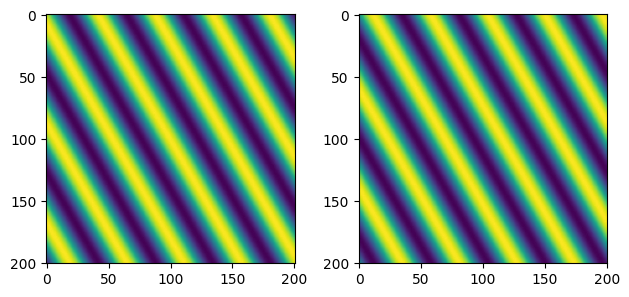

In [127]:
import matplotlib.pylab as plt
plt.subplot(1, 2, 1)
plt.imshow(raw[0]), 
plt.subplot(1, 2, 2)
plt.imshow(raw[1])
# plt.colorbar()
plt.tight_layout()
plt.show()

## 3. 预处理与 Radon 投影


去掉平面趋势，再减去余弦核平滑背景，最后再次去趋势。余弦核和边界延拓沿用原教程的规则，
用 NumPy 生成核、SciPy 卷积实现。圆外置零后调用 scikit-image 的 Radon。


只计算 `0–179°` 的投影轴，避免重复计算相差 180° 的方向；传播朝向由后面的相位差符号确定。
每个投影数组的形状为 **空间采样点 × 方向**。

In [128]:
def detrend_plane(image):
    # plane bg
    y, x = np.indices(image.shape)
    A = np.column_stack([x.ravel(), y.ravel(), np.ones(image.size)]) # [x1,y1,1] x [a,b,c].T=ax1+by1+c
    plane = (A @ np.linalg.lstsq(A, image.ravel(), rcond=None)[0]).reshape(image.shape) # lstsq-> least squares 
    return image - plane

def preprocess(image, halfsize):
    # 1 detrend plane bg
    image = detrend_plane(image)

    if halfsize > 0:
        y, x = np.ogrid[:2 * halfsize + 1, :2 * halfsize + 1]
        radius = np.hypot(y - halfsize - 1, x - halfsize - 1)
        kernel = np.cos(np.pi * radius / (2 * np.sqrt(2) * halfsize))
        background = fftconvolve(np.pad(image, halfsize, mode="edge"),
                                 kernel / kernel.sum(), mode="valid")
        image = image - background  # 2 detrend curve bg, kernel size = halfsize
        image = detrend_plane(image) # 3 detrend plane bg

    return image


In [129]:
# get circle shape
yy, xx = np.ogrid[:n, :n]
disk = (yy - n // 2)**2 + (xx - n // 2)**2 <= (n // 2)**2 
images = np.array([preprocess(image, smooth_halfsize) * disk for image in raw])

# radon transform
directions = np.arange(180, dtype=float) # RT 0-180 degree
s1, s2 = [radon(image, theta=directions, circle=True, preserve_range=True) for image in images]

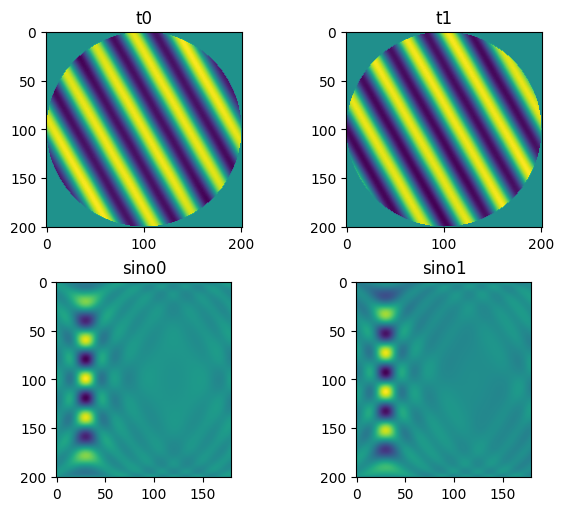

In [130]:
fig, axes = plt.subplots(2, 2, figsize=(6, 5), layout="constrained")

axes[0, 0].imshow(images[0]); axes[0, 0].set_title('t0')  # get circle shape
axes[0, 1].imshow(images[1]); axes[0, 1].set_title('t1')

axes[1, 0].imshow(s1); axes[1, 0].set_title('sino0')
axes[1, 1].imshow(s2); axes[1, 1].set_title('sino1')
plt.show()


## 4. 批量 FFT、交叉谱与候选方向

`axis=0` 沿空间采样轴计算，输出仍是复数系数。两幅影像的交叉谱
$H=C_1C_2^*$ 的角度是相位差 $\Delta\phi=\phi_1-\phi_2$，单位为弧度。
用原教程的 $|H|\,|\Delta\phi|$ 作为选峰得分，不把它当作物理波能量。

投影轴以 180° 为周期，所以选峰时将方向得分平铺，避免漏掉 0°/180° 接缝处的峰。

In [131]:
def cross_spectrum(C1, C2):
    cross = C1 * C2.conj() # C2 取共轭
    phase = np.angle(cross)
    return cross, phase, np.abs(cross) * np.abs(phase)


def periodic_peaks(values, prominence):
    count = len(values)
    peaks, _ = find_peaks(np.tile(values, 3), prominence=prominence) # 0 & 180 的时候可能有峰，所以要复制3份，取中间的.peak是对应的横坐标，也就是角度
    return peaks[(peaks >= count) & (peaks < 2 * count)] - count


q_fft = np.fft.rfftfreq(n, d=dx)
C1 = np.fft.rfft(s1, axis=0)
C2 = np.fft.rfft(s2, axis=0)
cross, phase, score = cross_spectrum(C1, C2)
direction_score = score.max(axis=0) # direction

direction_score /= direction_score.max() # norm direction scoure
peaks = periodic_peaks(direction_score, direction_prominence) # 峰保留到最大峰的0.3


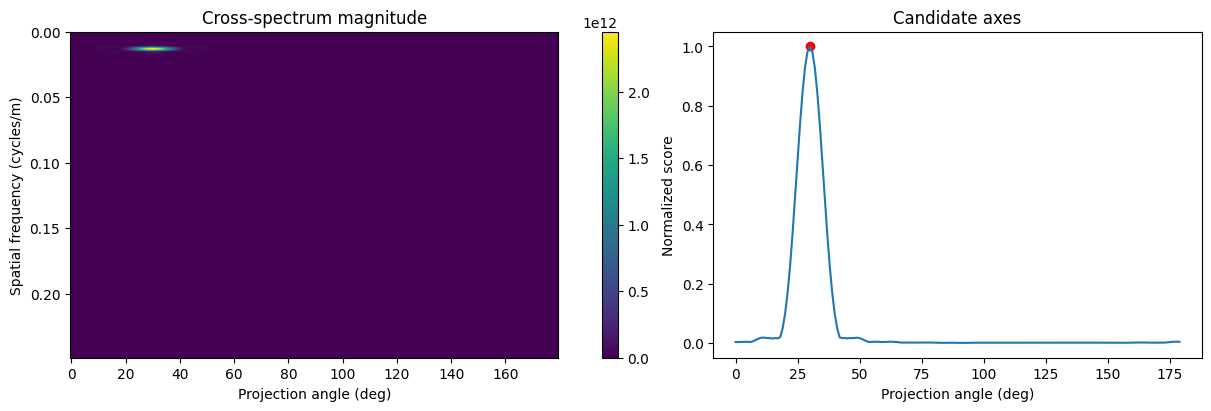

In [ ]:
# 1. 交叉谱幅值
fig, axes = plt.subplots(1,2, figsize=(12, 4), layout="constrained")
extent = [-0.5, 179.5, q_fft[0], q_fft[-1]]

ax = axes[0]

image = ax.imshow(np.abs(cross),
    origin="lower", aspect="auto", cmap="viridis",extent=extent)
ax.invert_yaxis()
ax.set(
    title="Cross-spectrum magnitude",
    xlabel="Projection angle (deg)",
    ylabel="Spatial frequency (cycles/m)",
)
fig.colorbar(image, ax=ax)


# 2. 方向得分与候选峰
ax = axes[1]
ax.plot(directions, direction_score)
ax.scatter(directions[peaks], direction_score[peaks], color="red")
ax.set(
    title="Candidate axes",
    xlabel="Projection angle (deg)",
    ylabel="Normalized score",
)
plt.show()

## 5. 指定频率上的精细 DFT

使用参数区的 `q_min`、`q_max`、`q_step` 直接设置空间频率网格，单位为 cycles/m，右端点 `q_max` 不包含。
`period_min`、`period_max` 用于后面实际估计周期的筛选。用矩阵乘法计算：

$$C(q,\theta)=\sum_n s(n,\theta)\exp(-j2\pi q\,n\Delta x).$$

保留 Nyquist 范围内的搜索位置。在粗选方向附近寻找精细方向峰，然后取各方向上得分最大的空间频率。

In [ ]:
def dft_at_frequencies(signals, frequencies, dx):
    positions = np.arange(signals.shape[0]) * dx
    return np.exp(-2j * np.pi * frequencies[:, None] * positions) @ signals

q_fine = np.arange(q_min, q_max, q_step) # fine frequency
q_fine = q_fine[(q_fine < 1 / (2 * dx))]  # Nyquist frequency
if q_fine.size == 0:
    raise ValueError("q_fine is too large")

refinements, candidates = [], []
for peak in peaks:
    # 之前得到的多个方向，每个方向取±10度，分别算每个度的 max score，得到这个方向的fine direction
    columns = (peak + np.arange(-angle_halfwidth, angle_halfwidth + 1)) % len(directions)
    F1 = dft_at_frequencies(s1[:, columns], q_fine, dx)
    F2 = dft_at_frequencies(s2[:, columns], q_fine, dx)
    _, fine_phase, fine_score = cross_spectrum(F1, F2)
    angle_score = fine_score.max(axis=0) # keep max score
    if angle_score.max() <= 0:
        continue
    angle_peaks, _ = find_peaks(angle_score / angle_score.max(), prominence=refinement_prominence) # 0.3 prominence
    
    # 得fine direction的max frequency，保存到candidates (refinement记录±10个方向的所有值)
    frequency_peaks = fine_score[:, angle_peaks].argmax(axis=0) # 
    refinement = dict(
        directions=directions[columns], # 本轮的 21 个方向
        C1=F1, # 频率数 × 21
        C2=F2,
        phase=fine_phase,
        score=fine_score)

    # 这个peak下面得到的fine angle和frequency都放到candidates，比如corse angle是20±10，那这个candidates可能会直接增加31,35,37
    for qi, di in zip(frequency_peaks, angle_peaks): 
        candidates.append(
            dict(
                projection_deg=directions[columns[di]],
                q=q_fine[qi],
                phase=fine_phase[qi, di],
                score=fine_score[qi, di],
                refinement=len(refinements),
                qi=qi,
                di=di))
                
    refinements.append(refinement)

if not candidates:
    raise ValueError("no candidate")

## 6. 从相位差、波长计算候选水深

假定两帧观测间没有额外的相位整周跳变，且信号代表线性传播波：

$$\omega=\frac{|\Delta\phi|}{|\Delta t|},\quad k=2\pi q,\quad
T=\frac{2\pi}{\omega},\quad c=\frac{\omega}{k},\quad
h=\frac{\operatorname{atanh}(\omega^2/(gk))}{k}.$$

相位差只在 $[-\pi,\pi]$ 内，不能仅凭两帧唯一确定是否漏掉整周；这里不自动解缠。
相位差除以时间间隔为负时，传播朝向相对投影轴翻转 180°。
`direction_deg` 为从东向起逆时针的传播朝向；`from_north_deg` 为从北向起顺时针的来向。

`valid_physics` 只检查这里写出的条件：色散反演存在有限解、周期在给定范围内、
水深大于 `depth_min`，且 $\omega^2/(gk)$ 大于 `linearity_min`。
所有候选都保留；该列不是与实测水深比较后的精度验证。

In [142]:
rows = []
for candidate in candidates:
    q, phase_shift = candidate["q"], candidate["phase"]
    omega = abs(phase_shift / delta_t)
    k = 2 * np.pi * q
    period = 2 * np.pi / omega if omega > 0 else np.inf
    speed = omega / k
    gamma = omega**2 / (g * k)
    depth = np.arctanh(gamma) / k if 0.3 < gamma < 0.9 else np.nan # Bergsma 2021 RSE
    direction = (candidate["projection_deg"] + (180 if phase_shift / delta_t < 0 else 0)) % 360


    rows.append(dict(
        direction_deg=direction,
        from_north_deg=(270 - direction) % 360,
        wavelength_m=1 / q,
        phase_shift_rad=phase_shift,
        period_s=period,
        celerity_m_s=speed,
        gamma=gamma,
        depth_m=depth,
        score=candidate["score"],
        valid_physics=bool(
            np.isfinite(depth) 
            and depth > depth_min
            and period_min <= period <= period_max 
            and gamma >= linearity_min)))
                
results = (pd.DataFrame(rows).sort_values("score", ascending=False)
           .drop_duplicates(["direction_deg", "wavelength_m"]).reset_index(drop=True))


valid_results = results.loc[results["valid_physics"]]

depth_weighted = (
    np.average(
        valid_results["depth_m"],
        weights=valid_results["gamma"],
    )
    if not valid_results.empty
    else np.nan
)

print(depth_weighted)

9.952992325579416


## 7. 查看得分最高候选的精细频谱

红线标记选中的空间频率。左图是两幅影像各自的系数模，中图是它们的相位差，右图是选峰得分。
这是最高得分候选的诊断图，不保证该候选通过上述物理条件。

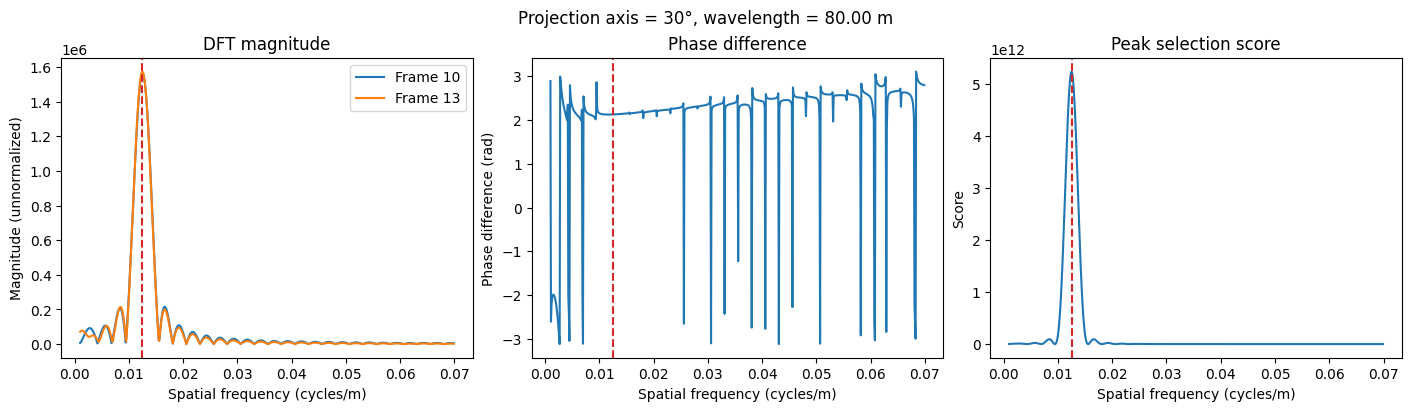

In [ ]:
best_candidate = max(candidates, key=lambda item: item["score"])
best = refinements[best_candidate["refinement"]]
qi, di = best_candidate["qi"], best_candidate["di"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
axes[0].plot(q_fine, np.abs(best["C1"][:, di]), label=f"Frame {frames[0]}")
axes[0].plot(q_fine, np.abs(best["C2"][:, di]), label=f"Frame {frames[1]}")
axes[0].set(title="DFT magnitude", ylabel="Magnitude (unnormalized)")
axes[0].legend()
axes[1].plot(q_fine, best["phase"][:, di])
axes[1].set(title="Phase difference", ylabel="Phase difference (rad)")
axes[2].plot(q_fine, best["score"][:, di])
axes[2].set(title="Peak selection score", ylabel="Score")
for ax in axes:
    ax.axvline(q_fine[qi], color="tab:red", linestyle="--")
    ax.set_xlabel("Spatial frequency (cycles/m)")
fig.suptitle(f"Projection axis = {best['directions'][di]:g}°, wavelength = {1 / q_fine[qi]:.2f} m")
plt.show()

## 8. 合成数据：已知真值与反演结果对照

合成数据由旁边的 `create_synthetic_wave.py` 生成：水深 $h=10$ m、波长 $\lambda=80$ m、
传播朝向为东向起逆时针 $30^\circ$，像元间距 2 m。先给定水深和波长，
再独立使用 $\omega^2=gk\tanh(kh)$ 确定传播频率，得到周期约 8.839 s。

亮度代理为 $I=1000+100\cos(k(x\cos\theta+y\sin\theta)-\omega t+0.2)+\epsilon$，
其中噪声标准差为 0.5。它是理想平面波的亮度代理，**不是 SWASH 仿真，也不是真实卫星光学成像**。
帧 10 和 13 的理论相位差约 2.132 rad，小于 $\pi$。完整走过读取、预处理、Radon 和选峰后，
结果会因有限窗口、空间采样、插值及频率搜索网格产生误差，不要求精确等于 10 m。

真值只用于这里的结果对照，**不参与选峰或水深反演**。SWASH 输入没有这些真值时跳过对照。

In [144]:
truth = metadata.get("GROUND_TRUTH")
if truth is not None:
    valid_results = results.loc[results["valid_physics"]]
    if valid_results.empty:
        raise ValueError("合成数据没有得到通过物理条件的候选，请检查前面的参数和频谱。")
    recovered = valid_results.iloc[0]
    quantities = ["depth_m", "wavelength_m", "period_s", "celerity_m_s"]
    comparison = pd.DataFrame({
        "Known truth": [truth[key] for key in quantities],
        "Recovered": [recovered[key] for key in quantities],
    }, index=quantities)
    comparison["Error"] = comparison["Recovered"] - comparison["Known truth"]
    comparison["Relative error (%)"] = 100 * comparison["Error"] / comparison["Known truth"]
    display(comparison)
    direction_error = abs((recovered["direction_deg"] - truth["direction_deg"] + 180) % 360 - 180)
    print(f"传播方向：真值 {truth['direction_deg']:g}°，反演 {recovered['direction_deg']:g}°，误差 {direction_error:g}°")
else:
    print("当前为 SWASH 输入，没有解析波真值对照。")

,Known truth,Recovered,Error,Relative error (%)
depth_m,10.000000,9.952992,-4.700767e-02,-4.700767e-01
wavelength_m,80.000000,80.000000,-2.842171e-14,-3.552714e-14
period_s,8.839275,8.853524,1.424959e-02,1.612076e-01
celerity_m_s,9.050516,9.035950,-1.456664e-02,-1.609482e-01


传播方向：真值 30°，反演 30°，误差 0°
